# FFNN classification — will this conjunction end up high risk?

**FYS-STK3155, Project 3.** Data: the ESA Collision Avoidance Challenge
conjunction data messages (CDMs).

## The question

Each *event* is a predicted close approach between an operational satellite and
another object. Over the days before the Time of Closest Approach (TCA) a
sequence of CDMs is issued, each with a refined collision risk
$r = \log_{10} P_c$. An operator must decide **two days before TCA** whether the
event deserves attention, because a collision-avoidance manoeuvre takes time to
plan and costs fuel.

We therefore predict, using only CDMs with `time_to_tca >= 2`:

$$ y = \mathbb{1}\left[\,r_{\text{final}} \ge -6\,\right], \qquad\text{i.e. } P_c \ge 10^{-6}. $$

## What makes this hard

## Data representation

All three models in this project (RNN, FFNN, XGBoost) share one pipeline in
`read_data.build_shared_datasets`: a single stratified event-level split, a
log10 transform of the heavy-tailed covariance columns, median imputation,
standardisation and a PCA on the ~96 orbital-geometry/covariance columns —
every step fitted on training events only. `time_to_tca`, the three
risk-derived columns and the two categoricals bypass the PCA, because PCA
keeps high-*variance* directions, not high-*predictive* ones, and `risk` is
the strongest predictor there is. The RNN consumes the resulting CDM-level
sequences; this notebook and XGBoost consume their **per-event aggregate**:
mean, standard deviation, first and last value of every sequence column, plus
the number of CDMs.

Only **66 of 8 293** labelled events are positive (0.80 %). That is about 13
positives per CV fold, which cannot support a stable comparison of nine
activation/initialisation combinations from a single split, so **every
model-selection number in this notebook is a 5-fold stratified
cross-validation mean ± standard deviation** on the development set
(`train_data.zip`, 66 positives; the folds are shared with the RNN and
XGBoost). The test set is the official competition set (`test_data.csv` joined
with `test_data_private.csv`: 2 167 events, 150 positive = 6.9 %, an enriched
sample), which is not touched until the very last section.

A false negative — a missed high-risk conjunction — is far more costly than a
false positive, which merely costs an analyst's time. The primary selection
metric is therefore $F_2$, which weights recall four times as heavily as
precision, and the training loss is class-weighted binary cross-entropy.

## Notebook outline

| § | Experiment |
|---|---|
| 1 | Setup, data loading, event-level split |
| 2 | Exploratory data analysis |
| 3 | Activation function × weight initialisation (3×3, `GridSearchCV`) |
| 4 | Loss function: weighted BCE vs. differentiable soft-$F_2$ |
| 5 | Network architecture: hidden layers × nodes (`GridSearchCV`) |
| 5b | Optimisers: Adam, RMSprop, plain SGD |
| 6 | Learning rate × L2 penalty (`GridSearchCV`) |
| 7 | Decision threshold selection |
| 8 | Ablation: is the current risk estimate doing all the work? |
| 9 | Learning curves of the selected model |
| 10 | Final held-out test evaluation |
| 11 | Benchmark against classical baselines |

## 1. Setup

In [ ]:
from __future__ import annotations

import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# `read_data`, `ffnn_core` and `plot_style` live next to this notebook.
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    fbeta_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict

import ffnn_core as fc
import plot_style as ps
import read_data as rd

warnings.filterwarnings("ignore", category=UserWarning)
ps.apply_style()

### Experiment configuration

Everything that the experiments hold fixed lives here, so that a comparison
never differs in more than the one thing it is supposed to compare.

In [ ]:
SEED = 3155

# --- data representation ---------------------------------------------------
VARIANCE_THRESHOLD = 0.95      # share of variance the PCA keeps (~49 of 96 columns)
INCLUDE_CURRENT_RISK = True    # see §8 for the ablation

# --- fixed training settings shared by every comparison --------------------
BASE_HIDDEN = (100, 100)
BASE_ACTIVATION = "relu"
BASE_INIT = "he"
BASE_LR = 1e-3
BASE_WEIGHT_DECAY = 0.0
BASE_OPTIMIZER = "adam"
BATCH_SIZE = 64
MAX_EPOCHS = 150
PATIENCE = 20                  # early stopping on validation PR-AUC
GRAD_CLIP = 5.0

#: Filled in by §4 once the loss function is chosen; every later `base_clf()`
#: call picks it up, so the architecture / hyperparameter / final-model
#: sections all train with the selected loss.
LOSS_OVERRIDES: dict = {}

# --- the project's experiment grid ("plotter vi skal ha.txt") --------------
ACT_INIT_HIDDEN = (100, 100)           # §3: input -> 100 -> 100 -> output
ARCH_LAYERS = [1, 2, 3]                # §5: hidden layers ...
ARCH_NODES = [25, 50, 75]              #     ... x nodes per hidden layer
FIXED_HIDDEN = (25,)                   # §5b, §6 onwards: input -> 25 -> output
OPT_LR, OPT_BATCH, OPT_EPOCHS = 1e-3, 100, 20   # §5b optimiser comparison
LEARNING_RATES = [1e-4, 1e-3, 1e-2]    # §6
L2_PENALTIES = [1e-5, 1e-4, 1e-3]      # §6 (may be widened if all look alike)

# --- cross-validation ------------------------------------------------------
CV_FOLDS = 5
N_JOBS = 7                     # parallel folds; each worker is single-threaded

RESULTS_DIR = Path("..") / "results" / "FFNN_classification"
#: Test-set probabilities of every model are stored here so that
#: `comparisons.ipynb` can plot all models together without retraining.
PRED_DIR = Path("..") / "results" / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "figures").mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "tables").mkdir(parents=True, exist_ok=True)

# One torch thread per process: the models are tiny, so parallelism pays off
# across CV folds rather than inside a single matrix multiply.
torch.set_num_threads(1)

fc.set_seed(SEED)
DEVICE = fc.get_device()
print(f"PyTorch {torch.__version__} | device: {DEVICE}")
print(f"Results -> {RESULTS_DIR.resolve()}")

### Loading the shared datasets

`build_shared_datasets` enforces the order that keeps the evaluation honest:

1. split **events** (stratified on the binary target),
2. fit the log-transform / imputer / scaler / PCA / one-hot encoder on the
   **training events' CDMs only**,
3. transform every split, then aggregate each event to one row.

Because each event is collapsed to exactly one row before anything is
fitted, two CDMs from the same event cannot end up in different splits; the
function asserts that the event ids are unique and the check is repeated
here.

In [3]:
from sklearn.preprocessing import StandardScaler

t0 = time.perf_counter()
shared = rd.build_shared_datasets(
    variance_threshold=VARIANCE_THRESHOLD, include_current_risk=INCLUDE_CURRENT_RISK,
    seed=SEED,
)
print(f"built in {time.perf_counter() - t0:.0f} s")

agg, meta = shared["aggregate"], shared["event_meta"]
y_dev, y_test = shared["y_class"]["train"], shared["y_class"]["test"]

# The aggregates are built from standardised columns but are not themselves
# standardised (a std is >= 0, a mean of a one-hot is in [0, 1]), so a scaler
# is fitted on the development rows and applied to the official test set.
#
# *Development set* = every labelled event of `train_data.zip`. All model
# selection happens here, through the group's shared 5-fold stratified CV
# (`shared["cv_folds"]`); the official test set stays frozen until §10.
scaler = StandardScaler().fit(agg["train"])
X_dev = scaler.transform(agg["train"]).astype(np.float32)
X_test = scaler.transform(agg["test"]).astype(np.float32)
feature_names = list(agg["train"].columns)

N_FEATURES = X_dev.shape[1]
print(f"PCA: {shared['n_components']} components for {VARIANCE_THRESHOLD:.0%} of the variance; "
      f"{len(shared['sequence_columns'])} sequence columns -> {N_FEATURES} aggregate features")
split_summary = pd.DataFrame(
    [
        {"split": name, "events": len(yy), "positives": int(yy.sum()),
         "positive rate": yy.mean()}
        for name, yy in [("development (train_data.zip)", y_dev),
                         ("official test (test_data + private)", y_test)]
    ]
)
print(split_summary.to_string(index=False))
ps.save_table(split_summary, "split_summary", RESULTS_DIR)

ids = shared["event_ids"]
# The two files number their events independently (test ids restart at 0), so the
# check is on CDM content, not ids: the files share no (event, time_to_tca) rows.
assert len(set(ids["train"])) == len(ids["train"]) and len(set(ids["test"])) == len(ids["test"])
print("\nevents are unique within each file; development and test come from separate files")

shared datasets: 10460 events | PCA keeps 49 of 96 columns for 95% variance | log10 on 15 columns | 77 sequence columns


built in 33 s
PCA: 49 components for 95% of the variance; 77 sequence columns -> 237 aggregate features
                              split  events  positives  positive rate
       development (train_data.zip)    8293         66       0.007959
official test (test_data + private)    2167        150       0.069220
  saved ../results/classification/tables/split_summary.csv

events are unique within each file; development and test come from separate files


### Class weighting and the cross-validation scheme

`pos_weight = n_neg / n_pos` is recomputed **inside each fold** from that
fold's training rows only (`pos_weight="auto"` in `TorchFFNNClassifier`), so
the weighting never sees the held-out fold.

In [ ]:
CV = shared["cv_folds"]     # the group's shared folds: list of (fit_idx, val_idx)
assert len(CV) == CV_FOLDS

#: Multi-metric scoring. `f2` is the selection metric; the rest are reported.
#: `f2`, `recall` and `precision` go through `predict()` and therefore use the
#: estimator's `threshold` (0.5 by default) — the threshold itself is tuned
#: separately in §7. `pr_auc` and `roc_auc` are threshold-free.
SCORING = {
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
}


def weighted_bce_scorer(estimator, X, y):
    """Negative validation BCE with the fold's own `pos_weight` (higher = better).

    This is the quantity the network minimises, so it is the "BCE loss" of the
    heatmaps. `GridSearchCV` maximises scores, hence the sign; `run_grid`
    flips it back to a positive loss.
    """
    p = np.clip(estimator.predict_proba(X)[:, 1], 1e-7, 1 - 1e-7)
    y = np.asarray(y, dtype=float)
    w = float(estimator.pos_weight_)
    return float(np.mean(w * y * np.log(p) + (1 - y) * np.log(1 - p)))


SCORING["bce"] = weighted_bce_scorer

print(f"dev pos_weight = {(len(y_dev) - y_dev.sum()) / y_dev.sum():.1f}")
print(f"{CV_FOLDS}-fold stratified CV -> ~{int(y_dev.sum()) // CV_FOLDS} positives per held-out fold")


def base_clf(**overrides) -> fc.TorchFFNNClassifier:
    """The shared FFNN configuration; experiments override one thing at a time."""
    params = dict(
        hidden_dims=BASE_HIDDEN,
        activation=BASE_ACTIVATION,
        initialization=BASE_INIT,
        loss_name="bce",
        pos_weight="auto",
        lr=BASE_LR,
        weight_decay=BASE_WEIGHT_DECAY,
        optimizer=BASE_OPTIMIZER,
        batch_size=BATCH_SIZE,
        max_epochs=MAX_EPOCHS,
        patience=PATIENCE,
        grad_clip=GRAD_CLIP,
        seed=SEED,
        device=DEVICE,
    )
    params.update(LOSS_OVERRIDES)
    params.update(overrides)
    return fc.TorchFFNNClassifier(**params)


def run_grid(estimator, param_grid, X, y, refit="roc_auc", cv=None) -> pd.DataFrame:
    """Run `GridSearchCV` and return a tidy mean ± std table.

    `GridSearchCV` handles the stratified folds, the parallelism and the score
    bookkeeping; the fitting inside each fold is still the PyTorch loop in
    `ffnn_core.train_model`.
    """
    gs = GridSearchCV(
        estimator, param_grid, scoring=SCORING, refit=refit,
        cv=cv or CV, n_jobs=N_JOBS, return_train_score=False,
    )
    t = time.perf_counter()
    gs.fit(X, y)
    elapsed = time.perf_counter() - t

    res = pd.DataFrame(gs.cv_results_)
    keep = [c for c in res.columns if c.startswith("param_")]
    keep += [f"mean_test_{m}" for m in SCORING] + [f"std_test_{m}" for m in SCORING]
    keep += ["mean_fit_time", "std_fit_time"]
    out = res[keep].copy()
    out.columns = [c.replace("mean_test_", "").replace("std_test_", "std_")
                   .replace("param_", "") for c in out.columns]
    out["bce"] = -out["bce"]        # scorer returns -loss; report the loss itself
    print(f"  {len(res)} configs x {CV_FOLDS} folds in {elapsed:.0f} s "
          f"(best {refit} = {gs.best_score_:.3f})")
    return out.sort_values(refit, ascending=False).reset_index(drop=True), gs


def cv_heatmaps(df, row_key, col_key, rows, cols, *, row_label, col_label,
                row_names=None, col_names=None, name=None, title_suffix=""):
    """Two heatmaps side by side: CV validation BCE loss and CV ROC-AUC.

    Same layout as the RNN notebook (`plot_rnn_architecture_heatmaps`):
    loss in YlOrRd, ROC-AUC in YlGnBu on a fixed 0.5-1.0 scale, mean over the
    CV folds written in every cell.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=False)
    panels = [
        ("bce", "YlOrRd", "Mean validation BCE loss", "CV validation loss", {}),
        ("roc_auc", "YlGnBu", "Mean validation ROC-AUC", "CV ROC-AUC", dict(vmin=0.5, vmax=1.0)),
    ]
    grids = {}
    for ax, (val, cmap, cbar, title, kw) in zip(axes, panels):
        grid = (df.pivot_table(index=row_key, columns=col_key, values=val, aggfunc="mean")
                  .reindex(index=rows, columns=cols))
        grids[val] = grid.copy()
        grid.index = row_names or rows
        grid.columns = col_names or cols
        sns.heatmap(grid, annot=True, fmt=".3f", cmap=cmap, linewidths=0.5,
                    cbar_kws={"label": cbar}, ax=ax, **kw)
        ax.set_title(title + title_suffix)
        ax.set_xlabel(col_label)
        ax.set_ylabel(row_label)
        ax.grid(False)
    fig.tight_layout()
    if name:
        ps.save_fig(fig, name, RESULTS_DIR)
    plt.show()
    return grids["bce"], grids["roc_auc"]


def cv_ensemble(estimator, X, y, cv=None):
    """Fit one model per CV fold; return out-of-fold probabilities and the models.

    The out-of-fold probabilities are what the decision threshold is tuned on
    (§7). Averaging the *same* fold models at test time keeps the probability
    scale the threshold was chosen on. A single model refitted on all of the
    development data stops at a different epoch and lands on a different
    probability scale, which §10 demonstrates.
    """
    from joblib import Parallel, delayed
    from sklearn.base import clone

    cv = cv or CV
    folds = list(cv.split(X, y)) if hasattr(cv, "split") else list(cv)

    def _fit(tr, va):
        t = time.perf_counter()
        m = clone(estimator).fit(X[tr], y[tr])
        return m, va, m.predict_proba(X[va])[:, 1], time.perf_counter() - t

    fitted = Parallel(n_jobs=min(N_JOBS, len(folds)))(delayed(_fit)(tr, va) for tr, va in folds)
    oof = np.zeros(len(y))
    models, fit_time = [], 0.0
    for m, va, p, t in fitted:
        oof[va] = p
        models.append(m)
        fit_time += t
    return oof, models, fit_time


def ensemble_proba(models, X):
    """Mean positive-class probability over a list of fitted fold models."""
    return np.mean([m.predict_proba(X)[:, 1] for m in models], axis=0)


def best_f2_threshold(y, proba):
    """Max-F2 threshold over the quantiles of `proba`; returns (threshold, f2)."""
    cand = np.unique(np.quantile(proba, np.linspace(0, 1, 401)))
    scores = np.array([fbeta_score(y, (proba >= t).astype(int), beta=2, zero_division=0)
                       for t in cand])
    k = int(np.argmax(scores))
    return float(cand[k]), float(scores[k])

## 2. Exploratory data analysis

Three things worth knowing before any model is fitted: how rare the positive
class is, how much history each event carries, and whether the classes are
separable at all in the raw feature space.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


  saved ../results/classification/figures/01_data_overview.png


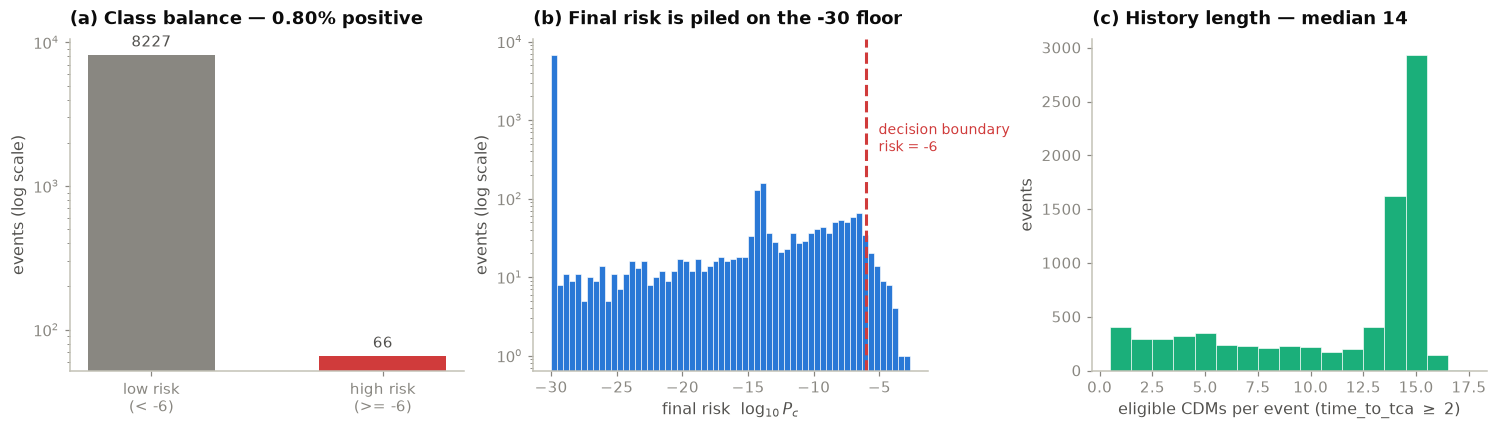

fraction of events whose final risk sits exactly on the -30 floor: 82.5%


In [5]:
meta_all = meta_dev = meta["train"]      # EDA on the development events only
y_all = y_dev

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))

# (a) class balance — a single hue, because the x-axis already names the classes
ax = axes[0]
counts = [int((y_all == 0).sum()), int((y_all == 1).sum())]
bars = ax.bar(["low risk\n(< -6)", "high risk\n(>= -6)"], counts,
              color=[ps.INK_MUTED, ps.STATUS["critical"]], width=0.55)
ax.bar_label(bars, fmt="%d", fontsize=9.5, color=ps.INK_SECONDARY, padding=3)
ax.set_yscale("log")
ax.set_ylabel("events (log scale)")
ax.set_title(f"(a) Class balance — {y_all.mean():.2%} positive")
ps.grid_y_only(ax)

# (b) final risk of every event, with the decision boundary marked
ax = axes[1]
y_cont = meta_all["final_risk"].values
ax.hist(y_cont, bins=60, color=ps.SERIES[0], edgecolor="white", linewidth=0.4)
ax.axvline(rd.HIGH_RISK_THRESHOLD, color=ps.STATUS["critical"], linewidth=2, linestyle="--")
ax.annotate("decision boundary\nrisk = -6", xy=(rd.HIGH_RISK_THRESHOLD, 0.7),
            xycoords=("data", "axes fraction"), xytext=(8, 0), textcoords="offset points",
            fontsize=9, color=ps.STATUS["critical"], va="center")
ax.set_yscale("log")
ax.set_xlabel(r"final risk  $\log_{10} P_c$")
ax.set_ylabel("events (log scale)")
ax.set_title("(b) Final risk is piled on the -30 floor")
ps.grid_y_only(ax)

# (c) how many CDMs an event contributes before the cutoff
ax = axes[2]
n_cdms = meta_all["n_cdms"].values
ax.hist(n_cdms, bins=np.arange(0.5, n_cdms.max() + 1.5), color=ps.SERIES[2],
        edgecolor="white", linewidth=0.4)
ax.set_xlabel("eligible CDMs per event (time_to_tca $\\geq$ 2)")
ax.set_ylabel("events")
ax.set_title(f"(c) History length — median {int(np.median(n_cdms))}")
ps.grid_y_only(ax)

ps.save_fig(fig, "01_data_overview", RESULTS_DIR)
plt.show()

print(f"fraction of events whose final risk sits exactly on the -30 floor: "
      f"{np.mean(y_cont <= -29.999):.1%}")

Two observations that shape everything below.

* **(b)** The risk scale is censored: 82 % of events end at exactly $-30$, the
  reporting floor. The classification target is therefore a thin tail of a
  heavily censored distribution — and the regression notebook has to confront
  the same floor directly.
* **(c)** Most events carry 10–17 CDMs before the cutoff; the aggregate
  features summarise that whole history (mean / std / first / last), so the
  model sees both the latest state and how it got there.

  saved ../results/classification/figures/02_feature_space.png


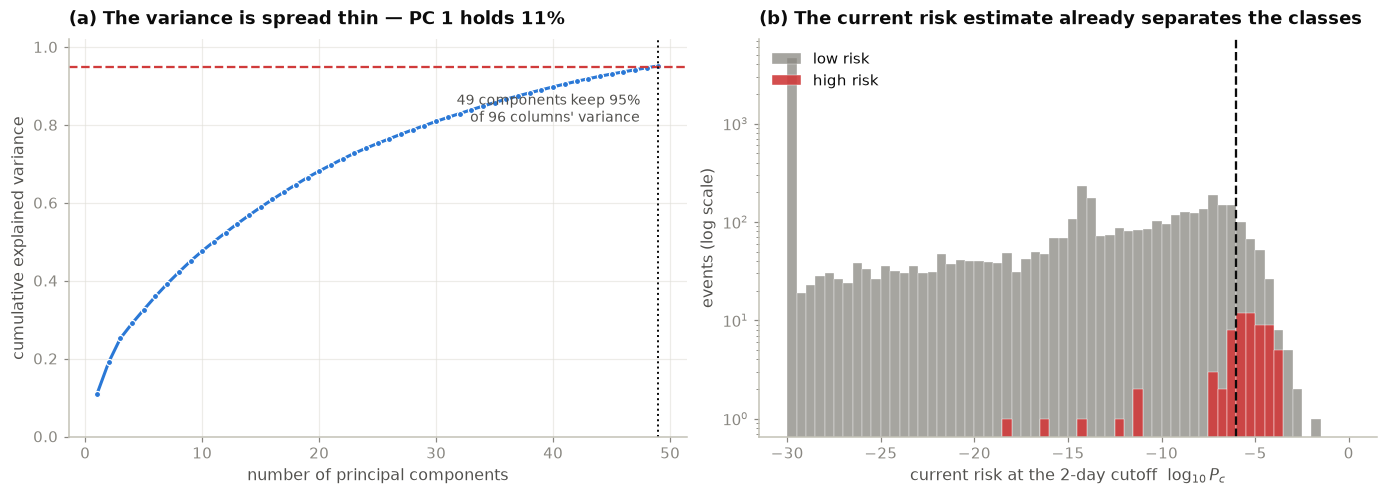

In [6]:
# How much does the PCA actually compress? And how informative is the one
# feature that bypasses it?
cum_var = np.cumsum(shared["explained_variance_ratio"])
n_pca_in = len(shared["pca_columns"])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax = axes[0]
ax.plot(np.arange(1, len(cum_var) + 1), cum_var, color=ps.SERIES[0], marker="o",
        markersize=4, markeredgecolor="white", markeredgewidth=0.8)
ax.axhline(VARIANCE_THRESHOLD, color=ps.STATUS["critical"], linestyle="--", linewidth=1.5)
ax.axvline(shared["n_components"], color=ps.INK, linestyle=":", linewidth=1.3)
ax.annotate(f"{shared['n_components']} components keep {VARIANCE_THRESHOLD:.0%}\nof {n_pca_in} columns' variance",
            xy=(shared["n_components"], VARIANCE_THRESHOLD), xytext=(-12, -36),
            textcoords="offset points", ha="right", fontsize=9, color=ps.INK_SECONDARY)
ax.set_xlabel("number of principal components")
ax.set_ylabel("cumulative explained variance")
ax.set_ylim(0, 1.02)
ax.set_title(f"(a) The variance is spread thin — PC 1 holds {cum_var[0]:.0%}")
ax.grid(True, alpha=0.6)

# The single most informative raw feature, by construction of the problem.
ax = axes[1]
risk_dev = meta_dev["last_risk"].values
bins = np.linspace(-30, 0, 61)
ax.hist(risk_dev[y_dev == 0], bins=bins, color=ps.INK_MUTED, alpha=0.75,
        label="low risk", edgecolor="white", linewidth=0.3)
ax.hist(risk_dev[y_dev == 1], bins=bins, color=ps.STATUS["critical"], alpha=0.9,
        label="high risk", edgecolor="white", linewidth=0.3)
ax.axvline(rd.HIGH_RISK_THRESHOLD, color=ps.INK, linewidth=1.5, linestyle="--")
ax.set_yscale("log")
ax.set_xlabel(r"current risk at the 2-day cutoff  $\log_{10} P_c$")
ax.set_ylabel("events (log scale)")
ax.set_title("(b) The current risk estimate already separates the classes")
ax.legend(loc="upper left")
ps.grid_y_only(ax)

ps.save_fig(fig, "02_feature_space", RESULTS_DIR)
plt.show()

Panel (a) is why the PCA keeps about half of the geometry columns rather
than a handful: no small set of directions dominates. Panel (b) is the reason
`risk` bypasses the PCA and the reason §8 runs an ablation: the value already
present in the last pre-cutoff CDM is *not* leakage — an operator can read it
two days before TCA — but it is so informative that it is worth asking how
much of the model's performance it alone accounts for.

## 3. Activation function × weight initialisation

A fixed `input → 100 → 100 → output` network, the same learning rate, batch
size, class weighting and early-stopping rule throughout; only the hidden-layer
activation (ReLU, Leaky ReLU, sigmoid) and the initialiser (He, Xavier, LeCun)
change. All 9 combinations are evaluated with `GridSearchCV` (5-fold stratified
CV) on the development set, and shown as BCE-loss and ROC-AUC heatmaps.

The initialisers all draw $W_{ij}\sim\mathcal{N}(0,\sigma^2)$ and differ only in
$\sigma^2$: LeCun $1/n_\text{in}$, Xavier $2/(n_\text{in}+n_\text{out})$, He
$2/n_\text{in}$ (slope-corrected for Leaky ReLU). Biases start at zero and the
output layer always uses Xavier, so the grid varies the hidden layers only.
The best combination is the one with the highest CV ROC-AUC.

In [ ]:
ACTIVATIONS = ["relu", "leaky_relu", "sigmoid"]
INITS = ["he", "xavier", "lecun"]

act_init_results, _ = run_grid(
    base_clf(hidden_dims=ACT_INIT_HIDDEN),
    {"activation": ACTIVATIONS, "initialization": INITS},
    X_dev, y_dev,
)
ps.save_table(act_init_results, "03_activation_initialization", RESULTS_DIR)
print(act_init_results[["activation", "initialization", "bce", "roc_auc", "std_roc_auc",
                        "pr_auc", "f2", "mean_fit_time"]].to_string(index=False))

In [ ]:
ACT_LABELS = {"sigmoid": "Sigmoid", "relu": "ReLU", "leaky_relu": "Leaky ReLU"}
INIT_LABELS = {"lecun": "LeCun", "xavier": "Xavier", "he": "He"}

cv_heatmaps(
    act_init_results, "activation", "initialization", ACTIVATIONS, INITS,
    row_label="Activation function", col_label="Weight initialisation",
    row_names=[ACT_LABELS[a] for a in ACTIVATIONS],
    col_names=[INIT_LABELS[i] for i in INITS],
    name="03_activation_initialization",
)

best_act_init = act_init_results.iloc[0]          # sorted by CV ROC-AUC
BEST_ACTIVATION = best_act_init["activation"]
BEST_INIT = best_act_init["initialization"]
print(f"selected: activation = {BEST_ACTIVATION}, initialization = {BEST_INIT} "
      f"(ROC-AUC = {best_act_init['roc_auc']:.3f} +/- {best_act_init['std_roc_auc']:.3f})")

Read the heatmaps with the fold-to-fold standard deviation in mind (column
`std_roc_auc` in the table above): with ~13 positives per held-out fold, a
difference of a few thousandths in ROC-AUC is not a resolved difference. The top
configuration is carried forward because a choice has to be made.

## 4. Loss function: adding explicit false-negative pressure

Weighted BCE penalises a missed positive $w = n_\text{neg}/n_\text{pos}
\approx 125$ times more than a false alarm, which is the textbook
cost-sensitive recipe (Elkan 2001). It is a *proper scoring rule*, so the
probabilities it produces are calibrated, and for calibrated probabilities the
$F_\beta$-optimal classifier is simply a threshold (Lipton, Elkan &
Naryanaswamy 2014) — which is what §7 does.

The ESA challenge, however, scores on $F_2$ directly, so it is worth asking
whether putting $F_2$ *into the training objective* helps. Three candidates:

**BCE + soft-$F_2$ penalty** — the same construction as the L1/L2 experiment
in the regression study, a penalty term added to the base loss:

$$\mathcal{L} = \text{BCE}_w + \lambda\,\big(1 - F_2^{\text{soft}}\big),\qquad
F_2^{\text{soft}} = \frac{5\,\mathrm{TP}}{5\,\mathrm{TP} + 4\,\mathrm{FN} + \mathrm{FP}},$$

with expected counts $\mathrm{TP}=\sum p_i y_i$, $\mathrm{FP}=\sum p_i(1-y_i)$,
$\mathrm{FN}=\sum(1-p_i)y_i$. $F_2^{\text{soft}}$ is the Tversky index of
Salehi et al. (2017) with weights 0.8 on FN and 0.2 on FP, and the additive
"BCE + Tversky" form is the standard combination in segmentation (Taghanaki
et al. 2019). $\lambda = 0$ recovers weighted BCE exactly.

**Focal loss** (Lin et al. 2017):
$\mathcal{L} = -\alpha_t (1-p_t)^{\gamma}\log p_t$ with $\alpha_t = w$ for
positives. The $(1-p_t)^\gamma$ factor silences the thousands of easy
negatives so the few hard positives dominate the gradient; $\gamma = 0$
recovers weighted BCE.

**MSE / soft-$F_2$** — the ratio form of the ESA score, kept for reference.

One practical point: $F_2^{\text{soft}}$ is *non-decomposable* — a property of
the whole batch, not a sum over samples. With 0.8 % positives, a batch of 64
contains a positive only ~40 % of the time, and on the other steps the term
contributes nothing. The $F_2$-based losses are therefore trained with a batch
of 512 (≈ 4 positives per batch on average), and weighted BCE is run at both
batch sizes so that the effect of the batch is separated from the effect of
the loss.

In [9]:
F2_BATCH_SIZE = 512
F2_LAMBDAS = [0.0, 0.1, 0.3, 1.0, 3.0, 10.0]
FOCAL_GAMMA = 2.0

LOSS_CONFIGS = [("Weighted BCE, batch 64", dict(loss_name="bce", batch_size=BATCH_SIZE))]
for lam in F2_LAMBDAS:
    label = "Weighted BCE, batch 512" if lam == 0 else f"BCE + {lam:g}·(1 − F2 soft)"
    LOSS_CONFIGS.append((label, dict(loss_name="bce_soft_f2", f2_lambda=lam, batch_size=F2_BATCH_SIZE)))
LOSS_CONFIGS += [
    (f"Focal, γ = {FOCAL_GAMMA:g}", dict(loss_name="focal", focal_gamma=FOCAL_GAMMA, batch_size=F2_BATCH_SIZE)),
    ("MSE / F2 soft (ratio)", dict(loss_name="soft_f2_mse", batch_size=F2_BATCH_SIZE)),
]

loss_rows = []
for label, kw in LOSS_CONFIGS:
    est = base_clf(activation=BEST_ACTIVATION, initialization=BEST_INIT, **kw)
    oof, _, fit_time = cv_ensemble(est, X_dev, y_dev)
    thr_best, f2_best = best_f2_threshold(y_dev, oof)
    pred_half = (oof >= 0.5).astype(int)
    loss_rows.append({
        "loss": label, "loss_name": kw["loss_name"],
        "f2_lambda": kw.get("f2_lambda", np.nan), "batch_size": kw["batch_size"],
        "pr_auc": average_precision_score(y_dev, oof),
        "roc_auc": roc_auc_score(y_dev, oof),
        "f2_at_0.5": fbeta_score(y_dev, pred_half, beta=2, zero_division=0),
        "recall_at_0.5": recall_score(y_dev, pred_half, zero_division=0),
        "precision_at_0.5": precision_score(y_dev, pred_half, zero_division=0),
        "best_f2": f2_best, "best_threshold": thr_best,
        "median_oof_proba": float(np.median(oof)),
        "fit_time_s": fit_time,
    })
    print(f"  {label:<28} F2@0.5 {loss_rows[-1]['f2_at_0.5']:.3f}  PR-AUC {loss_rows[-1]['pr_auc']:.3f}  "
          f"best F2 {f2_best:.3f} @ {thr_best:.3f}")

loss_results = pd.DataFrame(loss_rows)
ps.save_table(loss_results, "04_loss_comparison", RESULTS_DIR)

# Decision: weighted BCE stays the training loss. The alternatives move
# CV F2 by less than one fold-to-fold standard deviation (~0.10), so none is
# distinguishable from it on this data, and BCE is the only one of them that is
# a proper scoring rule -- its probabilities keep a meaningful scale, which §7
# relies on when it turns them into a review workload. Nothing is carried
# forward into LOSS_OVERRIDES.
BEST_LOSS_LABEL = "Weighted BCE, batch 64"

  Weighted BCE, batch 64       F2@0.5 0.222  PR-AUC 0.062  best F2 0.220 @ 0.496


  Weighted BCE, batch 512      F2@0.5 0.209  PR-AUC 0.080  best F2 0.222 @ 0.686


  BCE + 0.1·(1 − F2 soft)      F2@0.5 0.198  PR-AUC 0.076  best F2 0.222 @ 0.686


  BCE + 0.3·(1 − F2 soft)      F2@0.5 0.188  PR-AUC 0.076  best F2 0.222 @ 0.677


  BCE + 1·(1 − F2 soft)        F2@0.5 0.193  PR-AUC 0.062  best F2 0.216 @ 0.611


  BCE + 3·(1 − F2 soft)        F2@0.5 0.208  PR-AUC 0.061  best F2 0.235 @ 0.566


  BCE + 10·(1 − F2 soft)       F2@0.5 0.104  PR-AUC 0.048  best F2 0.169 @ 0.325


  Focal, γ = 2                 F2@0.5 0.209  PR-AUC 0.071  best F2 0.215 @ 0.507


  MSE / F2 soft (ratio)        F2@0.5 0.000  PR-AUC 0.039  best F2 0.178 @ 0.076
  saved ../results/classification/tables/04_loss_comparison.csv


  saved ../results/classification/figures/04_loss_comparison.png


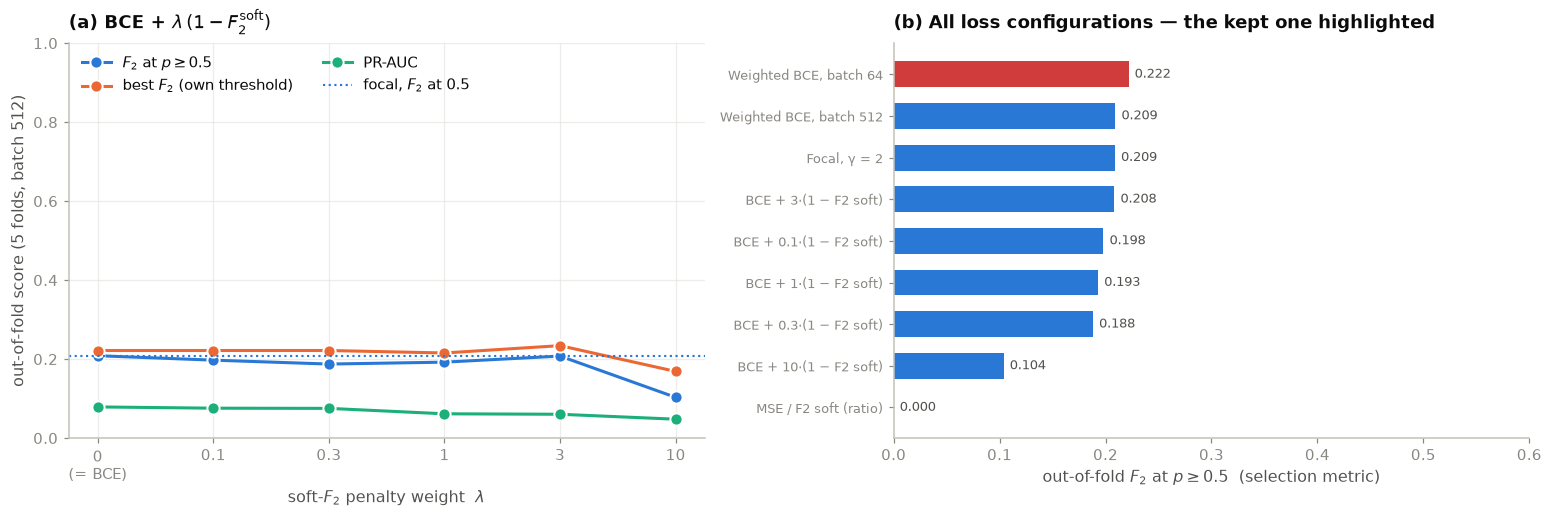

training loss kept for the rest of the notebook: Weighted BCE, batch 64
                   loss   pr_auc  roc_auc  f2_at_0.5  recall_at_0.5  precision_at_0.5  best_f2  median_oof_proba
 Weighted BCE, batch 64 0.061766 0.809286   0.221713       0.439394          0.074359 0.220365          0.007113
Weighted BCE, batch 512 0.079592 0.859513   0.209276       0.560606          0.059677 0.222458          0.083540
BCE + 0.1·(1 − F2 soft) 0.076395 0.854404   0.198020       0.545455          0.055814 0.222458          0.094862
BCE + 0.3·(1 − F2 soft) 0.075926 0.851870   0.188141       0.500000          0.053834 0.222458          0.088596
  BCE + 1·(1 − F2 soft) 0.062175 0.835374   0.192963       0.515152          0.055105 0.216216          0.107745
  BCE + 3·(1 − F2 soft) 0.061022 0.830427   0.208333       0.454545          0.065789 0.234783          0.072643
 BCE + 10·(1 − F2 soft) 0.048493 0.727938   0.103858       0.106061          0.095890 0.169492          0.000642
           Focal, γ = 2 

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# (a) the lambda sweep, with the two reference losses as horizontal guides
sweep = loss_results[loss_results["loss_name"] == "bce_soft_f2"].sort_values("f2_lambda")
xpos = np.arange(len(sweep))
ax = axes[0]
for k, (col, lbl) in enumerate([("f2_at_0.5", r"$F_2$ at $p \geq 0.5$"),
                                ("best_f2", r"best $F_2$ (own threshold)"),
                                ("pr_auc", "PR-AUC")]):
    ax.plot(xpos, sweep[col], marker="o", markersize=8, color=ps.SERIES[k], label=lbl,
            markeredgecolor="white", markeredgewidth=1.3)
focal = loss_results[loss_results["loss_name"] == "focal"].iloc[0]
ax.axhline(focal["f2_at_0.5"], color=ps.SERIES[0], linestyle=":", linewidth=1.4,
           label=r"focal, $F_2$ at 0.5")
ax.set_xticks(xpos, ["0\n(= BCE)"] + [f"{l:g}" for l in sweep["f2_lambda"].iloc[1:]])
ax.set_xlabel(r"soft-$F_2$ penalty weight  $\lambda$")
ax.set_ylabel("out-of-fold score (5 folds, batch 512)")
ax.set_title(r"(a) BCE + $\lambda\,(1 - F_2^{\mathrm{soft}})$")
ax.set_ylim(0, 1.0)
ax.legend(loc="upper left", ncols=2)
ax.grid(True, alpha=0.6)

# (b) every configuration, ranked by the selection metric
ax = axes[1]
ranked = loss_results.sort_values("f2_at_0.5")
best_label = BEST_LOSS_LABEL
colors = [ps.STATUS["critical"] if l == best_label else ps.SERIES[0] for l in ranked["loss"]]
bars = ax.barh(ranked["loss"], ranked["f2_at_0.5"], color=colors, height=0.62)
ax.bar_label(bars, fmt="{:.3f}".format, fontsize=8.5, color=ps.INK_SECONDARY, padding=4)
ax.set_xlabel(r"out-of-fold $F_2$ at $p \geq 0.5$  (selection metric)")
ax.set_xlim(0, max(0.6, ranked["f2_at_0.5"].max() * 1.3))
ax.set_title("(b) All loss configurations — the kept one highlighted")
ax.tick_params(axis="y", labelsize=8.5)
ps.grid_x_only(ax)

ps.save_fig(fig, "04_loss_comparison", RESULTS_DIR)
plt.show()

print(f"training loss kept for the rest of the notebook: {BEST_LOSS_LABEL}")
print(loss_results[["loss", "pr_auc", "roc_auc", "f2_at_0.5", "recall_at_0.5",
                    "precision_at_0.5", "best_f2", "median_oof_proba"]].to_string(index=False))

Two things to read off the table. First, compare the two weighted-BCE rows:
the change from batch 64 to 512 is itself an effect, separate from the loss.
Second, `median_oof_proba` shows where each loss puts its probability mass —
the ratio loss and large-$\lambda$ penalties pull the scale away from the 0.5
anchor, which is why they look poor at $p \ge 0.5$ but better at their own
best threshold. Since every alternative sits within one fold-to-fold standard
deviation of weighted BCE, weighted BCE is kept for the rest of the notebook:
it is the proper scoring rule of the set, and the recall/precision trade-off
is made explicitly at the threshold in §7 rather than baked into the loss.

## 5. Network architecture: hidden layers × nodes per layer

`GridSearchCV` over the number of hidden layers (1, 2, 3) and the number of
nodes in each hidden layer (25, 50, 75), with the activation and initialiser
selected in §3. The result is two heatmaps: CV validation BCE loss and CV
ROC-AUC.

In [ ]:
ARCH_GRID = [(n,) * L for L in ARCH_LAYERS for n in ARCH_NODES]

arch_results, _ = run_grid(
    base_clf(activation=BEST_ACTIVATION, initialization=BEST_INIT),
    {"hidden_dims": ARCH_GRID},
    X_dev, y_dev,
)
arch_results["hidden_layers"] = arch_results["hidden_dims"].map(len)
arch_results["nodes_per_layer"] = arch_results["hidden_dims"].map(lambda h: h[0])
arch_results["parameters"] = [
    fc.count_parameters(fc.FFNN(N_FEATURES, h, BEST_ACTIVATION, BEST_INIT, 1))
    for h in arch_results["hidden_dims"]
]
arch_results["hidden_dims"] = arch_results["hidden_dims"].map(str)
ps.save_table(arch_results, "05_architectures", RESULTS_DIR)
print(arch_results[["hidden_layers", "nodes_per_layer", "parameters", "bce", "roc_auc",
                    "std_roc_auc", "pr_auc", "mean_fit_time"]].to_string(index=False))

In [ ]:
cv_heatmaps(
    arch_results, "hidden_layers", "nodes_per_layer", ARCH_LAYERS, ARCH_NODES,
    row_label="Number of hidden layers", col_label="Nodes per hidden layer",
    name="05_architectures",
)

best_arch = arch_results.iloc[0]
print(f"best architecture by CV ROC-AUC: {int(best_arch['hidden_layers'])} layer(s) x "
      f"{int(best_arch['nodes_per_layer'])} nodes (ROC-AUC = {best_arch['roc_auc']:.3f})")

# The optimiser and learning-rate / penalty experiments below use the small
# fixed network input -> 25 -> output, as specified for the project, so that
# they are comparable with the RNN and XGBoost counterparts.
BEST_HIDDEN = FIXED_HIDDEN

## 5b. Optimisers

Network `input → 25 → output`, learning rate 0.001, batch size 100, 20 epochs,
no explicit penalty. Adam, RMSprop and plain (mini-batch) gradient descent are
compared with `GridSearchCV`; the bars show the CV mean with ±1 fold standard
deviation.

In [ ]:
OPT_LABELS = {"adam": "Adam", "rmsprop": "RMSprop", "sgd": "Plain SGD"}

opt_results, _ = run_grid(
    base_clf(hidden_dims=FIXED_HIDDEN, activation=BEST_ACTIVATION, initialization=BEST_INIT,
             lr=OPT_LR, batch_size=OPT_BATCH, max_epochs=OPT_EPOCHS, patience=OPT_EPOCHS),
    {"optimizer": list(OPT_LABELS)},
    X_dev, y_dev,
)
opt_results = opt_results.set_index("optimizer").loc[list(OPT_LABELS)].reset_index()
ps.save_table(opt_results, "05b_optimizers", RESULTS_DIR)
print(opt_results[["optimizer", "bce", "std_bce", "roc_auc", "std_roc_auc", "pr_auc"]]
      .to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
labels = [OPT_LABELS[o] for o in opt_results["optimizer"]]
for ax, col, pal, ylab, title in [
    (axes[0], "bce", "YlOrRd", "Mean validation BCE loss", "CV validation loss"),
    (axes[1], "roc_auc", "YlGnBu", "Mean validation ROC-AUC", "CV ROC-AUC"),
]:
    sns.barplot(x=labels, y=opt_results[col], hue=labels, palette=pal, legend=False, ax=ax)
    ax.errorbar(np.arange(len(labels)), opt_results[col], yerr=opt_results["std_" + col],
                fmt="none", color="black", capsize=5)
    ax.set_title(title)
    ax.set_xlabel("Optimizer")
    ax.set_ylabel(ylab)
axes[1].set_ylim(0.0, 1.0)
fig.tight_layout()
ps.save_fig(fig, "05b_optimizers", RESULTS_DIR)
plt.show()

BEST_OPTIMIZER = opt_results.sort_values("roc_auc", ascending=False).iloc[0]["optimizer"]
print(f"best optimiser by CV ROC-AUC: {OPT_LABELS[BEST_OPTIMIZER]}")

## 6. Learning rate × L2 penalty

With the activation and initialiser fixed and the network `input → 25 → output`,
`GridSearchCV` sweeps the Adam learning rate (10⁻⁴, 10⁻³, 10⁻²) against the L2
penalty strength (10⁻⁵, 10⁻⁴, 10⁻³): 9 combinations, 5 folds each. The penalty
$\lambda\sum W^2$ is added to the loss and runs over the weight matrices only
(biases are not penalised), as in the theory. The grid may be shifted if every
cell looks the same.

In [ ]:
hp_results, hp_search = run_grid(
    base_clf(hidden_dims=FIXED_HIDDEN, activation=BEST_ACTIVATION,
             initialization=BEST_INIT, optimizer="adam"),
    {"lr": LEARNING_RATES, "l2_lambda": L2_PENALTIES},
    X_dev, y_dev,
)
hp_results["lr"] = hp_results["lr"].astype(float)
hp_results["l2_lambda"] = hp_results["l2_lambda"].astype(float)
ps.save_table(hp_results, "06_lr_l2_penalty", RESULTS_DIR)
print(hp_results[["lr", "l2_lambda", "bce", "roc_auc", "std_roc_auc", "pr_auc"]]
      .to_string(index=False))

In [ ]:
cv_heatmaps(
    hp_results, "l2_lambda", "lr", L2_PENALTIES, LEARNING_RATES,
    row_label="L2 penalty strength", col_label="Learning rate",
    row_names=[f"{p:.0e}" for p in L2_PENALTIES],
    col_names=[f"{l:.0e}" for l in LEARNING_RATES],
    name="06_lr_l2_penalty_heatmap",
)

BEST_LR = float(hp_results.iloc[0]["lr"])          # sorted by CV ROC-AUC
BEST_L2 = float(hp_results.iloc[0]["l2_lambda"])
print(f"selected: lr = {BEST_LR:g}, L2 penalty = {BEST_L2:g}")

Read the two heatmaps together: the loss shows how well the network fits the
(class-weighted) objective, ROC-AUC how well it ranks events. Because early
stopping already regularises the network, the penalty axis may turn out to
matter less than the learning-rate axis — check the fold standard deviations
(`std_roc_auc` in `06_lr_l2_penalty.csv`) before drawing that conclusion.

## 7. Choosing the decision threshold

Classifying at $p \ge 0.5$ is an arbitrary choice, and a poor one when the
positive class is under 1 %. The threshold is a free parameter of the
*decision rule*, not of the model, and it is selected here from **out-of-fold**
predictions on the development set — each event scored by a model that never
saw it — and then **frozen** before the test set is opened.

Two candidate rules:

1. **Max-$F_2$** — the threshold maximising $F_2$ out of fold.
2. **95 % recall** — the highest threshold that still catches 95 % of high-risk
   events, i.e. the cheapest rule meeting a safety requirement.

In [ ]:
final_estimator = base_clf(
    hidden_dims=BEST_HIDDEN, activation=BEST_ACTIVATION,
    initialization=BEST_INIT, lr=BEST_LR, l2_lambda=BEST_L2, optimizer="adam",
)
oof_proba, fold_models, fold_fit_time = cv_ensemble(final_estimator, X_dev, y_dev)
print(f"out-of-fold PR-AUC {average_precision_score(y_dev, oof_proba):.3f} | "
      f"ROC-AUC {roc_auc_score(y_dev, oof_proba):.3f}")

grid = np.unique(np.concatenate([[0.0], np.quantile(oof_proba, np.linspace(0, 1, 801)), [1.0]]))
rows = []
for thr in grid:
    pred = (oof_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dev, pred, labels=[0, 1]).ravel()
    rows.append({
        "threshold": thr,
        "f2": fbeta_score(y_dev, pred, beta=2, zero_division=0),
        "recall": recall_score(y_dev, pred, zero_division=0),
        "precision": precision_score(y_dev, pred, zero_division=0),
        "false_negatives": int(fn), "false_positives": int(fp),
        "frac_reviewed": pred.mean(),
    })
thr_df = pd.DataFrame(rows)
ps.save_table(thr_df, "07_threshold_sweep", RESULTS_DIR)

THR_MAX_F2 = float(thr_df.loc[thr_df["f2"].idxmax(), "threshold"])
meets = thr_df[thr_df["recall"] >= 0.95]
THR_95_RECALL = float(meets.loc[meets["frac_reviewed"].idxmin(), "threshold"]) if len(meets) else 0.0

# Out of fold, a few high-risk events receive probabilities close to zero, so
# 95 % recall may only be reachable by reviewing (almost) every event. Record
# whether that is the case, because it changes how the rule should be read.
row_95_tmp = thr_df.iloc[(thr_df["threshold"] - THR_95_RECALL).abs().idxmin()]
RECALL_95_REACHABLE = bool(row_95_tmp["frac_reviewed"] < 0.5)
max_recall_below_half = thr_df[thr_df["frac_reviewed"] <= 0.5]["recall"].max()
print(f"highest out-of-fold recall while reviewing <= 50 % of events: {max_recall_below_half:.1%}")
if not RECALL_95_REACHABLE:
    print("95 % recall is NOT reachable without reviewing essentially every event; "
          "the rule degenerates to 'flag everything' and is reported as such.")

row_f2 = thr_df.iloc[(thr_df["threshold"] - THR_MAX_F2).abs().idxmin()]
row_95 = thr_df.iloc[(thr_df["threshold"] - THR_95_RECALL).abs().idxmin()]
thr_summary = pd.DataFrame([
    {"rule": "max F2", **row_f2.to_dict()},
    {"rule": "95% recall", **row_95.to_dict()},
])
ps.save_table(thr_summary, "07_threshold_rules", RESULTS_DIR)
print(thr_summary.to_string(index=False))

# `max F2` is the primary operating threshold: F2 is the stated selection
# metric, and the 95%-recall rule is reported alongside as the safety-first
# alternative. Frozen here, before the test set is touched.
PRIMARY_THRESHOLD = THR_MAX_F2
print(f"\nFROZEN primary threshold = {PRIMARY_THRESHOLD:.4f} (max-F2 rule)")
print(f"       alternative        = {THR_95_RECALL:.4f} (95%-recall rule"
      f"{'' if RECALL_95_REACHABLE else ' -- degenerate, flags everything'})")

  saved ../results/classification/figures/07_threshold_selection.png


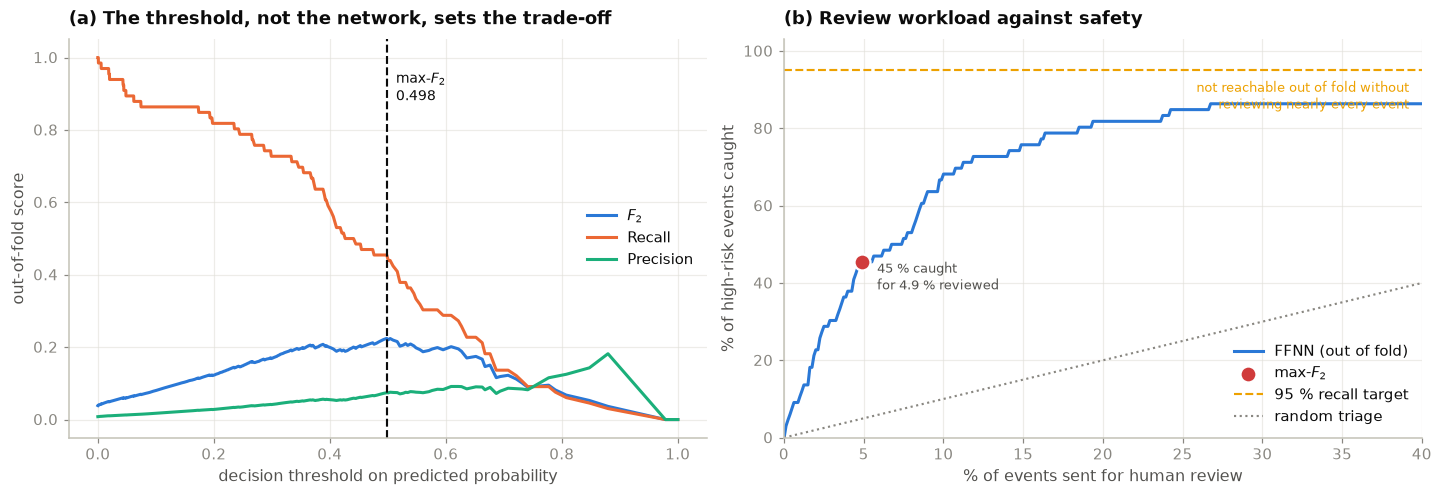

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
ax.plot(thr_df["threshold"], thr_df["f2"], color=ps.SERIES[0], label=r"$F_2$")
ax.plot(thr_df["threshold"], thr_df["recall"], color=ps.SERIES[1], label="Recall")
ax.plot(thr_df["threshold"], thr_df["precision"], color=ps.SERIES[2], label="Precision")
ax.axvline(PRIMARY_THRESHOLD, color=ps.INK, linestyle="--", linewidth=1.4)
ax.annotate(f"max-$F_2$\n{PRIMARY_THRESHOLD:.3f}", xy=(PRIMARY_THRESHOLD, 0.92),
            xycoords=("data", "axes fraction"), xytext=(6, 0), textcoords="offset points",
            fontsize=9, color=ps.INK, va="top")
ax.set_xlabel("decision threshold on predicted probability")
ax.set_ylabel("out-of-fold score")
ax.set_title("(a) The threshold, not the network, sets the trade-off")
ax.legend(loc="center right")
ax.grid(True, alpha=0.6)

# Operational view: what fraction of events must a human look at to catch what
# fraction of the real high-risk ones?
ax = axes[1]
ax.plot(100 * thr_df["frac_reviewed"], 100 * thr_df["recall"],
        color=ps.SERIES[0], label="FFNN (out of fold)")
markers = [(PRIMARY_THRESHOLD, r"max-$F_2$", ps.STATUS["critical"], "o")]
if RECALL_95_REACHABLE:
    markers.append((THR_95_RECALL, "95 % recall", ps.SERIES[3], "s"))
for thr, name, colour, marker in markers:
    r = thr_df.iloc[(thr_df["threshold"] - thr).abs().idxmin()]
    ax.scatter(100 * r["frac_reviewed"], 100 * r["recall"], s=110, color=colour,
               edgecolors="white", linewidths=1.5, zorder=4, marker=marker, label=name)
    ax.annotate(f"{100 * r['recall']:.0f} % caught\nfor {100 * r['frac_reviewed']:.1f} % reviewed",
                xy=(100 * r["frac_reviewed"], 100 * r["recall"]),
                textcoords="offset points", xytext=(10, -18), fontsize=8.5,
                color=ps.INK_SECONDARY)
if not RECALL_95_REACHABLE:
    ax.axhline(95, color=ps.SERIES[3], linestyle="--", linewidth=1.4, label="95 % recall target")
    ax.annotate("not reachable out of fold without\nreviewing nearly every event",
                xy=(0.98, 95), xycoords=("axes fraction", "data"), xytext=(0, -6),
                textcoords="offset points", ha="right", va="top", fontsize=8.5,
                color=ps.SERIES[3])
# A random triage rule reviews x % of events and catches x % of positives.
ax.plot([0, 100], [0, 100], color=ps.INK_MUTED, linestyle=":", linewidth=1.4,
        label="random triage")
ax.set_xlim(0, max(40, 100 * row_95["frac_reviewed"] + 10) if RECALL_95_REACHABLE else 40)
ax.set_ylim(0, 103)
ax.set_xlabel("% of events sent for human review")
ax.set_ylabel("% of high-risk events caught")
ax.set_title("(b) Review workload against safety")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.6)

ps.save_fig(fig, "07_threshold_selection", RESULTS_DIR)
plt.show()

## 8. Ablation — how much of this is just the current risk estimate?

§2(b) showed that the risk value in the last pre-cutoff CDM already separates
the classes. Here the whole shared pipeline is rebuilt with
`include_current_risk=False`, which removes `risk`, `max_risk_estimate` and
`max_risk_scaling` from the pass-through block (they never enter the PCA),
leaving only orbital geometry, covariance, timing and object metadata.

Neither setting is leakage: both use information available two days before TCA.
They answer different questions.

In [ ]:
abl_rows = []
for include_risk in (True, False):
    sh = shared if include_risk else rd.build_shared_datasets(
        variance_threshold=VARIANCE_THRESHOLD, include_current_risk=False,
        seed=SEED, verbose=False)
    sc = StandardScaler().fit(sh["aggregate"]["train"])
    Xd = sc.transform(sh["aggregate"]["train"]).astype(np.float32)
    yd = sh["y_class"]["train"]
    res, _ = run_grid(
        base_clf(hidden_dims=BEST_HIDDEN, activation=BEST_ACTIVATION,
                 initialization=BEST_INIT, lr=BEST_LR, l2_lambda=BEST_L2, optimizer="adam"),
        {"hidden_dims": [BEST_HIDDEN]}, Xd, yd,
    )
    r = res.iloc[0]
    abl_rows.append({
        "current risk in features": include_risk,
        "features": Xd.shape[1],
        "f2": r["f2"], "std_f2": r["std_f2"],
        "recall": r["recall"], "precision": r["precision"],
        "pr_auc": r["pr_auc"], "std_pr_auc": r["std_pr_auc"], "roc_auc": r["roc_auc"],
    })

ablation = pd.DataFrame(abl_rows)
ps.save_table(ablation, "08_risk_ablation", RESULTS_DIR)
print(ablation.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
mets = ["f2", "pr_auc", "roc_auc", "recall"]
mlabels = [r"$F_2$", "PR-AUC", "ROC-AUC", "Recall"]
x = np.arange(len(mets))
w = 0.36
for k, inc in enumerate([True, False]):
    r = ablation[ablation["current risk in features"] == inc].iloc[0]
    bars = ax.bar(x + (k - 0.5) * w, [r[m] for m in mets], w * 0.9, color=ps.SERIES[k],
                  label="with current risk" if inc else "geometry only")
    ax.bar_label(bars, fmt="{:.3f}".format, fontsize=8.5, color=ps.INK_SECONDARY, padding=2)
ax.set_xticks(x, mlabels)
ax.set_ylabel("5-fold CV mean")
ax.set_ylim(0, 1.12)
ax.set_title("Ablation: dropping the pre-cutoff risk estimate")
ax.legend(ncols=2, loc="upper left")
ps.grid_y_only(ax)
ps.save_fig(fig, "08_risk_ablation", RESULTS_DIR)
plt.show()

## 9. Learning curves of the selected model

A single fit on the fit part of CV fold 1 (80 % of the development set), monitored on its held-out
split, to show what one training run actually does. Early stopping watches
validation PR-AUC and the best state is restored, so the curves continue past
the chosen epoch only to show what would have happened.

In [ ]:
fc.set_seed(SEED)
# One CV fold split into fit / monitor parts, just to draw the curves.
fit_idx, mon_idx = shared["cv_folds"][0]
X_train, y_train = X_dev[fit_idx], y_dev[fit_idx]
X_val, y_val = X_dev[mon_idx], y_dev[mon_idx]
pw = float((len(y_train) - y_train.sum()) / y_train.sum())
curve_model = fc.FFNN(N_FEATURES, BEST_HIDDEN, BEST_ACTIVATION, BEST_INIT, 1)
lk = {"loss_name": "bce", "f2_lambda": 0.0, "focal_gamma": 2.0, "batch_size": BATCH_SIZE}
lk.update(LOSS_OVERRIDES)
curve_model, history = fc.train_model(
    curve_model, X_train, y_train, X_val, y_val,
    task="classification", loss_name=lk["loss_name"], pos_weight=pw,
    f2_lambda=lk["f2_lambda"], focal_gamma=lk["focal_gamma"],
    lr=BEST_LR, l2_lambda=BEST_L2, optimizer="adam", batch_size=lk["batch_size"],
    max_epochs=MAX_EPOCHS, patience=PATIENCE, grad_clip=GRAD_CLIP, device=DEVICE,
)
hist_df = pd.DataFrame({k: history[k] for k in
                        ("train_loss", "val_loss", "val_score", "epoch_time", "cum_time")})
hist_df.insert(0, "epoch", np.arange(1, len(hist_df) + 1))
ps.save_table(hist_df, "09_learning_curves", RESULTS_DIR)
print(f"stopped after {history['n_epochs']} epochs; best epoch {history['best_epoch']}; "
      f"{history['total_time']:.1f} s; {fc.count_parameters(curve_model)} parameters")

  saved ../results/classification/figures/09_learning_curves.png


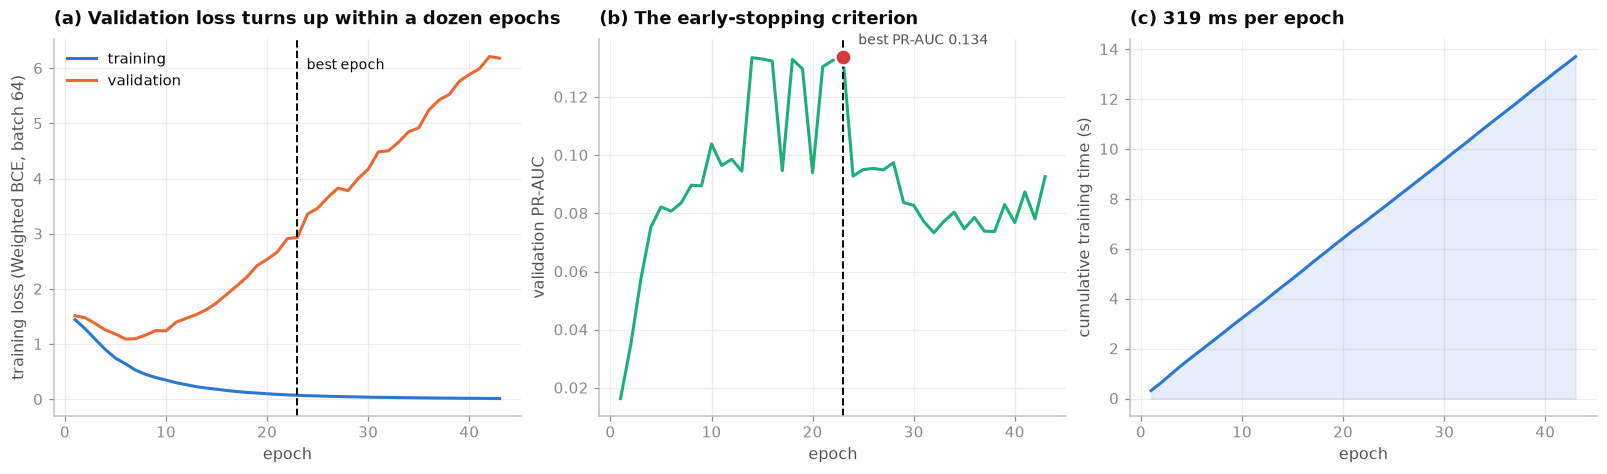

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))
epochs = hist_df["epoch"]

ax = axes[0]
ax.plot(epochs, hist_df["train_loss"], color=ps.SERIES[0], label="training")
ax.plot(epochs, hist_df["val_loss"], color=ps.SERIES[1], label="validation")
ax.axvline(history["best_epoch"], color=ps.INK, linestyle="--", linewidth=1.3)
ax.annotate("best epoch", xy=(history["best_epoch"], 0.95),
            xycoords=("data", "axes fraction"), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color=ps.INK, va="top")
ax.set_xlabel("epoch")
ax.set_ylabel(f"training loss ({BEST_LOSS_LABEL})")
ax.set_title("(a) Validation loss turns up within a dozen epochs")
ax.legend()
ax.grid(True, alpha=0.6)

ax = axes[1]
ax.plot(epochs, hist_df["val_score"], color=ps.SERIES[2])
ax.axvline(history["best_epoch"], color=ps.INK, linestyle="--", linewidth=1.3)
ax.scatter([history["best_epoch"]], [history["best_score"]], s=110,
           color=ps.STATUS["critical"], edgecolors="white", linewidths=1.5, zorder=4)
ax.annotate(f"best PR-AUC {history['best_score']:.3f}",
            xy=(history["best_epoch"], history["best_score"]),
            textcoords="offset points", xytext=(10, 8), fontsize=9, color=ps.INK_SECONDARY)
ax.set_xlabel("epoch")
ax.set_ylabel("validation PR-AUC")
ax.set_title("(b) The early-stopping criterion")
ax.grid(True, alpha=0.6)

ax = axes[2]
ax.plot(epochs, hist_df["cum_time"], color=ps.SERIES[0])
ax.fill_between(epochs, 0, hist_df["cum_time"], color=ps.SERIES[0], alpha=0.12)
ax.set_xlabel("epoch")
ax.set_ylabel("cumulative training time (s)")
ax.set_title(f"(c) {hist_df['epoch_time'].mean() * 1000:.0f} ms per epoch")
ax.grid(True, alpha=0.6)

ps.save_fig(fig, "09_learning_curves", RESULTS_DIR)
plt.show()

Validation loss bottoms out within about ten epochs and then climbs steadily,
while PR-AUC jumps around from epoch to epoch — with only ~13 positives in the
monitoring fold, a single event changing rank moves it by several points.
With ~53 positives in the fit part the network memorises them quickly;
early stopping is doing nearly all of the regularising, which is exactly why
§6 found weight decay to be inert.

## 10. Final evaluation on the official test set

Everything above used only the development set. The final predictor is the
**average of the five fold models from §7** — the models whose out-of-fold
predictions the threshold was tuned on — evaluated once on the 2 167 official test
events with the threshold frozen in §7.

A single network refitted on all development data is also scored, to show why
the ensemble is used: with early stopping, a refit stops at a different epoch
and its probabilities land on a different scale, so a threshold chosen out of
fold no longer means the same thing (compare the "fraction flagged" line).

In [ ]:
# (i) The CV ensemble: the five fold models from §7, averaged. These are the
#     models whose out-of-fold predictions the threshold was tuned on.
test_proba = ensemble_proba(fold_models, X_test)
final_train_time = fold_fit_time

# (ii) For comparison, one model refitted on the whole development set.
fc.set_seed(SEED)
refit_model = base_clf(hidden_dims=BEST_HIDDEN, activation=BEST_ACTIVATION,
                       initialization=BEST_INIT, lr=BEST_LR, l2_lambda=BEST_L2, optimizer="adam")
t0 = time.perf_counter()
refit_model.fit(X_dev, y_dev)
refit_train_time = time.perf_counter() - t0
test_proba_refit = refit_model.predict_proba(X_test)[:, 1]


def classification_report_row(name, y_true, proba, threshold, train_time=np.nan):
    """Every metric the report needs, for one model at one threshold."""
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "model": name,
        "threshold": threshold,
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": fbeta_score(y_true, pred, beta=1, zero_division=0),
        "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "pr_auc": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "true_positives": int(tp), "false_negatives": int(fn),
        "false_positives": int(fp), "true_negatives": int(tn),
        "frac_reviewed": pred.mean(),
        "train_time_s": train_time,
    }


final_rows = [
    classification_report_row(f"FFNN CV-ensemble @ max-F2 ({PRIMARY_THRESHOLD:.3f})",
                              y_test, test_proba, PRIMARY_THRESHOLD, final_train_time),
    classification_report_row(f"FFNN CV-ensemble @ 95% recall ({THR_95_RECALL:.3f})",
                              y_test, test_proba, THR_95_RECALL, final_train_time),
    classification_report_row("FFNN CV-ensemble @ 0.5 (untuned)",
                              y_test, test_proba, 0.5, final_train_time),
    classification_report_row(f"FFNN refit on all dev @ max-F2 ({PRIMARY_THRESHOLD:.3f})",
                              y_test, test_proba_refit, PRIMARY_THRESHOLD, refit_train_time),
]
final_results = pd.DataFrame(final_rows)
ps.save_table(final_results, "10_final_test_results", RESULTS_DIR)
print(final_results.drop(columns=["train_time_s"]).to_string(index=False))

print(f"\nfraction of test events flagged at p >= {PRIMARY_THRESHOLD:.3f}: "
      f"ensemble {np.mean(test_proba >= PRIMARY_THRESHOLD):.1%} vs "
      f"refit {np.mean(test_proba_refit >= PRIMARY_THRESHOLD):.1%} "
      f"(out of fold it was {row_f2['frac_reviewed']:.1%})")

# Accuracy is reported once, only to show why it is useless here.
acc = ((test_proba >= PRIMARY_THRESHOLD).astype(int) == y_test).mean()
print(f"\n(accuracy at the primary threshold: {acc:.4f}; always predicting "
      f"'low risk' scores {1 - y_test.mean():.4f} — this is why accuracy is not used)")

In [ ]:
# Same look as the RNN notebook: one figure per plot, thick line, dashed grey
# chance line, light grid, counts in a blue confusion-matrix heatmap.
y_test_i = np.asarray(y_test).astype(int)

# --- ROC -------------------------------------------------------------------
fpr, tpr, _ = roc_curve(y_test_i, test_proba)
auc = roc_auc_score(y_test_i, test_proba)
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=False)
ax.plot(fpr, tpr, linewidth=2, label=f"FFNN (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate / Recall")
ax.set_title("ROC curve for FFNN on the official test set")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
ps.save_fig(fig, "10_final_roc", RESULTS_DIR)
plt.show()

# --- Precision-recall ------------------------------------------------------
prec, rec, _ = precision_recall_curve(y_test_i, test_proba)
ap = average_precision_score(y_test_i, test_proba)
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=False)
ax.plot(rec, prec, linewidth=2, label=f"FFNN (AP = {ap:.3f})")
ax.axhline(y_test_i.mean(), linestyle="--", color="gray",
           label=f"Random classifier (AP = {y_test_i.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_ylim(0, 1.02)
ax.set_title("Precision-recall curve for FFNN on the official test set")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
ps.save_fig(fig, "10_final_pr", RESULTS_DIR)
plt.show()

# --- Confusion matrix ------------------------------------------------------
cm = confusion_matrix(y_test_i, (test_proba >= PRIMARY_THRESHOLD).astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=False)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", square=True,
            cbar_kws={"label": "Number of events"},
            xticklabels=["Low risk (0)", "High risk (1)"],
            yticklabels=["Low risk (0)", "High risk (1)"], ax=ax)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"Confusion matrix, threshold = {PRIMARY_THRESHOLD:.4f}")
ax.grid(False)
fig.tight_layout()
ps.save_fig(fig, "10_final_confusion", RESULTS_DIR)
plt.show()

# --- Store test predictions for comparisons.ipynb ----------------------------
np.savez(PRED_DIR / "ffnn.npz", y_true=y_test_i, proba=test_proba,
         threshold=PRIMARY_THRESHOLD)
print(f"  saved {PRED_DIR / 'ffnn.npz'}")

## 11. Benchmark against classical baselines

The FFNN is only interesting if it beats simpler things. Every baseline sees
exactly the same features, the same development set and the same frozen test
set, and each follows the same protocol as the FFNN — five fold models,
threshold tuned on their out-of-fold predictions, test prediction from their
average — so the comparison is like for like.

The most important baseline is not a learned model at all: **flag the event if
the risk already reported at the 2-day cutoff is at or above $-6$.** That rule
needs no training and is what an operator could do with a spreadsheet.

In [22]:
BASELINES = {
    "Always 'low risk'": DummyClassifier(strategy="constant", constant=0),
    "Logistic regression": LogisticRegression(max_iter=5000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample",
                                            random_state=SEED, n_jobs=N_JOBS),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
}

bench_rows = []

# (i) the untrained operator rule, on the raw (unscaled) risk column
raw_risk_test = meta["test"]["last_risk"].values
bench_rows.append(classification_report_row(
    "Rule: current risk >= -6", y_test, raw_risk_test, rd.HIGH_RISK_THRESHOLD, 0.0))

# (ii) trained baselines — same protocol as the FFNN: 5 fold models, threshold
#      from their out-of-fold predictions, test prediction from their average.
for name, model in BASELINES.items():
    if name.startswith("Always"):
        model.fit(X_dev, y_dev)
        bench_rows.append(classification_report_row(
            name, y_test, model.predict_proba(X_test)[:, 1], 0.5, 0.0))
        continue
    oof, models, tt = cv_ensemble(model, X_dev, y_dev)
    thr, _ = best_f2_threshold(y_dev, oof)
    bench_rows.append(classification_report_row(
        name, y_test, ensemble_proba(models, X_test), thr, tt))

# (iii) the selected FFNN
bench_rows.append(classification_report_row(
    "FFNN (this notebook)", y_test, test_proba, PRIMARY_THRESHOLD, final_train_time))

benchmark = pd.DataFrame(bench_rows).sort_values("f2", ascending=False).reset_index(drop=True)
ps.save_table(benchmark, "11_benchmark", RESULTS_DIR)
print(benchmark[["model", "f2", "recall", "precision", "pr_auc", "roc_auc",
                 "false_negatives", "false_positives", "frac_reviewed",
                 "train_time_s"]].to_string(index=False))

  saved ../results/classification/tables/11_benchmark.csv
                   model       f2   recall  precision   pr_auc  roc_auc  false_negatives  false_positives  frac_reviewed  train_time_s
Rule: current risk >= -6 0.739075 0.766667   0.646067 0.665077 0.944455               35               63       0.082141      0.000000
       Gradient boosting 0.732759 0.793333   0.561321 0.622778 0.954077               31               93       0.097831     15.908221
           Random forest 0.521862 0.493333   0.678899 0.625493 0.952757               76               35       0.050300     38.725249
     Logistic regression 0.500659 0.506667   0.477987 0.493482 0.912899               74               83       0.073373      2.636040
    FFNN (this notebook) 0.418883 0.420000   0.414474 0.396200 0.842201               87               89       0.070143     25.674023
       Always 'low risk' 0.000000 0.000000   0.000000 0.069220 0.500000              150                0       0.000000      0.0000

  saved ../results/classification/figures/11_benchmark.png


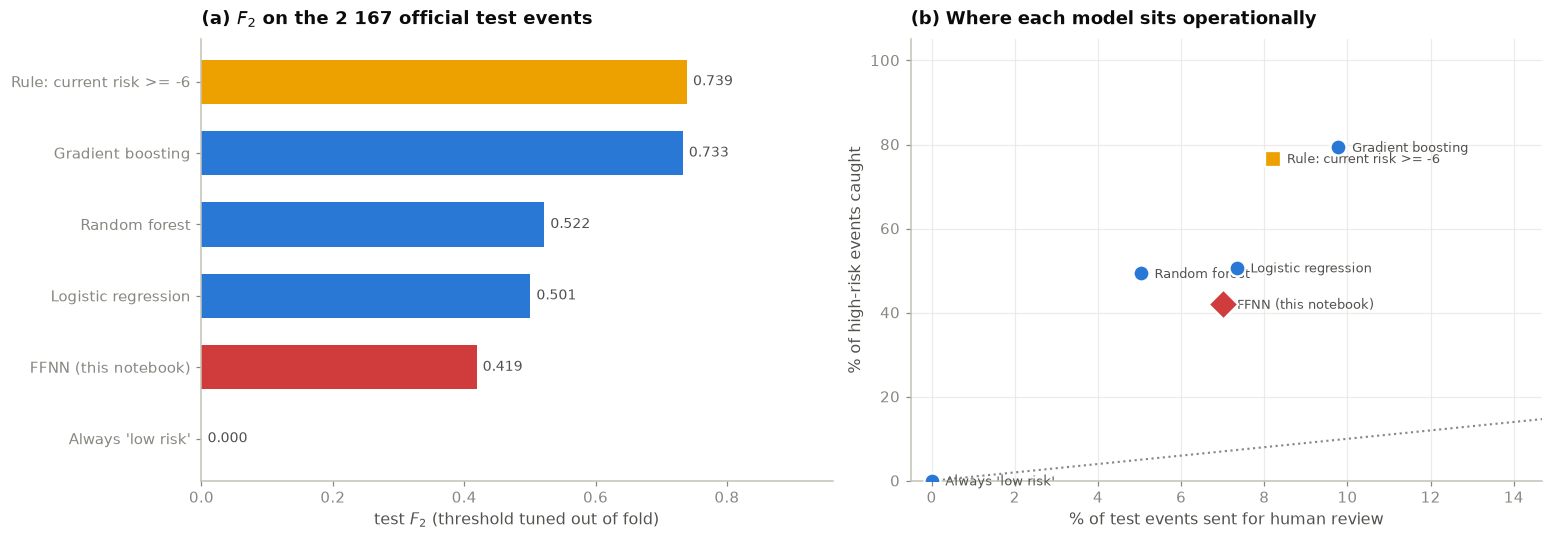

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
order = benchmark.sort_values("f2")
colors = [ps.STATUS["critical"] if "FFNN" in m else
          (ps.SERIES[3] if m.startswith("Rule") else ps.SERIES[0])
          for m in order["model"]]

ax = axes[0]
bars = ax.barh(order["model"], order["f2"], color=colors, height=0.62)
ax.bar_label(bars, fmt="{:.3f}".format, fontsize=9, color=ps.INK_SECONDARY, padding=4)
ax.set_xlabel(r"test $F_2$ (threshold tuned out of fold)")
ax.set_xlim(0, max(0.75, order["f2"].max() * 1.3))
ax.set_title(r"(a) $F_2$ on the 2 167 official test events")
ps.grid_x_only(ax)

ax = axes[1]
for _, r in benchmark.iterrows():
    is_ffnn = "FFNN" in r["model"]
    is_rule = r["model"].startswith("Rule")
    ax.scatter(100 * r["frac_reviewed"], 100 * r["recall"],
               s=190 if is_ffnn else 110,
               color=ps.STATUS["critical"] if is_ffnn else (ps.SERIES[3] if is_rule else ps.SERIES[0]),
               edgecolors="white", linewidths=1.5, zorder=4,
               marker="D" if is_ffnn else ("s" if is_rule else "o"))
    ax.annotate(r["model"], (100 * r["frac_reviewed"], 100 * r["recall"]),
                textcoords="offset points", xytext=(9, -3), fontsize=8.5,
                color=ps.INK_SECONDARY)
ax.plot([0, 100], [0, 100], color=ps.INK_MUTED, linestyle=":", linewidth=1.4)
ax.set_xlabel("% of test events sent for human review")
ax.set_ylabel("% of high-risk events caught")
ax.set_xlim(-0.5, max(12, 100 * benchmark["frac_reviewed"].max() * 1.5))
ax.set_ylim(0, 105)
ax.set_title("(b) Where each model sits operationally")
ax.grid(True, alpha=0.6)

ps.save_fig(fig, "11_benchmark", RESULTS_DIR)
plt.show()

## Summary

* With 66 positive events in the whole dataset, **fold-to-fold scatter swamps
  the differences between activation functions, initialisers and
  architectures.** The honest reading of §3 and §5 is that none of these
  choices is resolvable at this sample size; reporting a single validation
  split would have manufactured a winner out of noise.
* **The decision threshold matters far more than the network.** Moving it
  traverses the entire recall/precision range (§7), while every architectural
  choice moves $F_2$ by less than one standard deviation. A safety rule of
  95 % recall is not attainable out of fold without flagging nearly every
  event: a few high-risk events look entirely benign two days out.
* **Putting $F_2$ into the loss is a second-order effect** (§4): the
  penalty, focal and ratio variants all rank the events about as well as
  weighted BCE; they mostly move the probability scale, which the threshold
  step absorbs anyway.
* **Early stopping is the operative regulariser.** Validation PR-AUC peaks
  within a few epochs (§9), which is why the weight-decay sweep is flat (§6).
* The **current risk estimate carries most of the signal** (§8), and the
  untrained rule "flag if current risk $\ge -6$" is a genuinely competitive
  baseline (§11) — a result worth stating plainly rather than burying.

Limitations: 10 positive events in the test split, so every test number has a
standard error of several points; the architecture and threshold were chosen on
the same development set, so the test score is mildly optimistic; and the PCA
threshold (95 %) was fixed rather than tuned.